# Chapter 10 실습 답안. 분류 분석으로 주문 취소 여부 예측하기

## 제출 정보
- 이름: 박재선
- GitHub ID: lilypark0930-lab
- 작성일: 2026-11-18
- 최종 Notebook URL: https://github.com/lilypark0930-lab/llm-data-analysis-study/blob/main/chapter10/chapter10.ipynb

## 핵심 결론

| 항목 | 결과 |
| --- | --- |
| 분류 문제 | 주문 생성 직후 `completed=0`, `cancelled=1` 예측 |
| 모델링 데이터 | 248건 (완료 184건 74.2%, 취소 64건 25.8%) |
| Validation에서 고정한 선택 | Logistic Regression, Threshold 0.30 |
| Final Test | Accuracy 0.420, Precision 0.289, Recall 0.846, F1 0.431 |
| 최종 사용 판단 | **현재 사용 보류** |


# 10장. 분류 분석으로 주문 취소 여부 예측하기

이 노트북은 완료 주문과 취소 주문만 사용해 `is_cancelled`를 예측하는 이진 분류 실습입니다.

## 학습 목표

- `completed=0`, `cancelled=1`로 타깃 범위를 명확하게 정의합니다.
- `refunded`와 기타 상태를 이진 분류 대상에서 제외합니다.
- 병합의 키 관계, 행 수, 미매칭을 검증합니다.
- train, validation, test를 분리합니다.
- Dummy 기준 모델, Logistic Regression, Random Forest를 비교합니다.
- validation에서 모델과 임계값을 선택하고 test는 최종 평가에 한 번만 사용합니다.
- 예측 결과에서 고객명 등 불필요한 개인정보를 제외합니다.

## 1. 프로젝트 루트와 실행 환경 설정

전처리 파일이 없다면 프로젝트 루트에서 먼저 다음 명령을 실행하세요.

```bash
python scripts/prepare_ch10_data.py
```

In [1]:
from pathlib import Path
import sys

import pandas as pd


def find_project_root(start_path):
    start_path = Path(start_path).resolve()
    for candidate in [start_path, *start_path.parents]:
        if (candidate / 'requirements.txt').exists() and (candidate / 'scripts').exists():
            return candidate
    raise FileNotFoundError('프로젝트 루트 폴더를 찾을 수 없습니다.')


PROJECT_ROOT = find_project_root(Path.cwd())
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
REPORT_DIR = PROJECT_ROOT / 'reports'
REPORT_DIR.mkdir(parents=True, exist_ok=True)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print('Python 실행 파일:', sys.executable)
print('프로젝트 루트:', PROJECT_ROOT)
print('전처리 데이터 폴더:', PROCESSED_DIR)
print('보고서 폴더:', REPORT_DIR)

Python 실행 파일: C:\dev\llm-data-analysis-study\.venv\Scripts\python.exe
프로젝트 루트: C:\dev\llm-data-analysis-study
전처리 데이터 폴더: C:\dev\llm-data-analysis-study\data\processed
보고서 폴더: C:\dev\llm-data-analysis-study\reports


In [2]:
import os
import subprocess

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

IMAGE_DIR = PROJECT_ROOT / 'notebooks' / 'ch10' / 'images'
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

SURFACE = '#fcfcfb'
INK = '#0b0b0b'
MUTED = '#52514e'
GRID = '#e4e3df'
BLUE = '#2a78d6'
ORANGE = '#eb6834'
AQUA = '#1baf7a'
NEUTRAL = '#9a9994'

plt.rcParams.update({
    'font.family': 'Malgun Gothic',
    'axes.unicode_minus': False,
    'figure.facecolor': SURFACE,
    'axes.facecolor': SURFACE,
    'axes.edgecolor': GRID,
    'axes.labelcolor': MUTED,
    'axes.titlecolor': INK,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'xtick.color': MUTED,
    'ytick.color': MUTED,
    'font.size': 10,
})


def clean_axes(ax, grid_axis='y'):
    ax.spines[['top', 'right', 'left']].set_visible(False)
    ax.tick_params(length=0)
    if grid_axis:
        ax.grid(axis=grid_axis, color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)


def save_figure(fig, filename):
    fig.savefig(IMAGE_DIR / filename, dpi=160, bbox_inches='tight', facecolor=SURFACE)
    plt.show()

## 2. 전처리 데이터 확인과 불러오기

이 장에서는 `customers_clean.csv`, `orders_clean.csv`, `order_items_clean.csv`를 사용합니다.

In [3]:
required_files = [
    PROCESSED_DIR / 'customers_clean.csv',
    PROCESSED_DIR / 'orders_clean.csv',
    PROCESSED_DIR / 'order_items_clean.csv',
]

missing_files = [path for path in required_files if not path.exists()]
if missing_files:
    raise FileNotFoundError(
        '전처리 파일이 없습니다: '
        + ', '.join(str(path) for path in missing_files)
        + '. 먼저 python scripts/prepare_ch10_data.py를 실행하세요.'
    )

customers = pd.read_csv(PROCESSED_DIR / 'customers_clean.csv')
orders = pd.read_csv(PROCESSED_DIR / 'orders_clean.csv')
order_items = pd.read_csv(PROCESSED_DIR / 'order_items_clean.csv')

print('customers:', customers.shape, customers.columns.tolist())
print('orders:', orders.shape, orders.columns.tolist())
print('order_items:', order_items.shape, order_items.columns.tolist())

customers: (150, 6) ['customer_id', 'name', 'gender', 'age', 'city', 'signup_date']
orders: (300, 7) ['order_id', 'customer_id', 'order_date', 'payment_method', 'order_status', 'order_month', 'order_dayofweek']
order_items: (764, 6) ['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price', 'line_total']


## 3. 주문 상태와 타깃 범위 확인

이번 실습은 완료 주문과 취소 주문만 비교합니다.

- `completed` → 0
- `cancelled` → 1
- `refunded`와 기타 상태 → 학습 대상에서 제외

In [4]:
status_summary = (
    orders['order_status']
    .value_counts(dropna=False)
    .rename_axis('order_status')
    .reset_index(name='order_count')
)
status_summary

,order_status,order_count
0,completed,184
1,cancelled,64
2,refunded,52


## 답안 1. 분류 문제 정의

- 타깃: `is_cancelled` (주문 취소 여부)
- 0의 의미: `completed` (완료 주문)
- 1의 의미: `cancelled` (취소 주문)
- 제외한 상태: `refunded` 52건과 그 밖의 상태
- 예측 단위: 주문 1건
- 예측 시점: 주문 생성 직후 (교육용 가정)
- 예측 시점에 사용할 수 있는 정보: 고객 나이·성별·도시, 가입 후 경과일, 주문 월·요일, 결제수단, 주문 상품 수·총수량·주문금액
- 예측 이후에만 알 수 있어 제외한 정보: `order_status`, `is_cancelled`, `cancel_reason`, `cancelled_at`, 취소 이후 생성되는 정보

### 나의 해석과 판단
환불은 결제가 완료된 뒤 발생하는 별도의 사건이므로 완료(0)나 취소(1)에 임의로 합치면 타깃의 의미가 흐려집니다. 그래서 완료와 취소만 비교했습니다. 예측 시점을 주문 생성 직후로 정한 이유는 취소가 일어나기 전에 위험을 파악해야 예측을 활용할 수 있기 때문입니다.

## 4. 분류 데이터와 병합 검증표 생성

공통 함수는 주문 특징 집계, 안전한 병합, 시간 순서 점검, 타깃 생성까지 수행합니다.

In [5]:
from src.classification import (
    build_classification_dataset,
    target_distribution,
)

(
    model_data,
    numeric_features,
    categorical_features,
    merge_checks,
    data_quality_checks,
) = build_classification_dataset(
    customers=customers,
    orders=orders,
    order_items=order_items,
)

target_dist = target_distribution(model_data)

print('모델링 데이터:', model_data.shape)
print('숫자형 feature:', numeric_features)
print('범주형 feature:', categorical_features)
display(target_dist)
display(merge_checks)
display(data_quality_checks)

모델링 데이터: (248, 16)
숫자형 feature: ['age', 'item_count', 'total_quantity', 'order_amount', 'order_month', 'order_dayofweek', 'days_since_signup']
범주형 feature: ['gender', 'city', 'payment_method']


,is_cancelled,class_label,count,ratio
0,0,completed,184,0.7419
1,1,cancelled,64,0.2581


,merge,before_rows,after_rows,row_count_preserved,unmatched_count,status
0,order_id → order_item_features,248,248,True,0,PASS
1,customer_id → customers,248,248,True,0,PASS


,check_item,count
0,binary_target_rows,248
1,completed_rows,184
2,cancelled_rows,64
3,excluded_status_rows,52
4,line_total_mismatch,0
5,negative_days_since_signup,45
6,missing_order_item_features,0
7,missing_customer_match,0
8,status_scope:completed,184
9,status_scope:cancelled,64


In [6]:
from src.classification import build_order_item_features

expected_line_total = order_items['quantity'] * order_items['unit_price']
order_item_features = build_order_item_features(order_items)

order_item_checks = pd.DataFrame({
    'check_item': [
        'line_total과 quantity × unit_price 불일치',
        'quantity 0 이하',
        'unit_price 0 이하',
        '주문 특징 order_id 중복',
    ],
    'count': [
        int((order_items['line_total'] - expected_line_total).abs().gt(1e-6).sum()),
        int(order_items['quantity'].le(0).sum()),
        int(order_items['unit_price'].le(0).sum()),
        int(order_item_features['order_id'].duplicated().sum()),
    ],
})
display(order_item_checks)

missing_summary = (
    model_data[numeric_features + categorical_features]
    .isna().sum().rename_axis('feature').reset_index(name='missing_count')
)
display(missing_summary.query('missing_count > 0'))

,check_item,count
0,line_total과 quantity × unit_price 불일치,0
1,quantity 0 이하,0
2,unit_price 0 이하,0
3,주문 특징 order_id 중복,0


,feature,missing_count
6,days_since_signup,45


## 5. 데이터 누수 확인

`order_status`와 `is_cancelled`는 입력 feature에 포함되면 안 됩니다.

In [7]:
features = numeric_features + categorical_features
leakage_columns = {'order_status', 'is_cancelled'}
leakage_found = sorted(leakage_columns.intersection(features))

if leakage_found:
    raise ValueError(f'데이터 누수 위험 컬럼이 포함되었습니다: {leakage_found}')

print('사용 feature:', features)
print('데이터 누수 컬럼 없음')

사용 feature: ['age', 'item_count', 'total_quantity', 'order_amount', 'order_month', 'order_dayofweek', 'days_since_signup', 'gender', 'city', 'payment_method']
데이터 누수 컬럼 없음


In [8]:
from src.classification import FORBIDDEN_FEATURES, build_feature_audit

feature_audit = build_feature_audit(numeric_features, categorical_features)
forbidden_overlap = sorted(set(features) & FORBIDDEN_FEATURES)
assert not forbidden_overlap, f'금지 feature 포함: {forbidden_overlap}'

print('금지 feature와 입력 feature의 겹침:', len(forbidden_overlap), '건')
display(feature_audit)

금지 feature와 입력 feature의 겹침: 0 건


,column,selected,role,reason
0,age,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
1,item_count,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
2,total_quantity,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
3,order_amount,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
4,order_month,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
5,order_dayofweek,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
6,days_since_signup,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
7,gender,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
8,city,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
9,payment_method,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정


## 답안 2. Feature Contract와 Leakage Audit

### 사용한 숫자형 Feature
`age`, `item_count`, `total_quantity`, `order_amount`, `order_month`, `order_dayofweek`, `days_since_signup`

### 사용한 범주형 Feature
`gender`, `city`, `payment_method`

### 금지 Feature

```text
order_status
is_cancelled
order_id
customer_id
product_id
cancel_reason
cancelled_at
취소 이후 정보
```

### 나의 해석과 판단
파일에 컬럼이 있다고 해서 예측 시점에 그 값을 알 수 있는 것은 아닙니다. 예를 들어 `order_status`는 주문의 결과이므로 입력에 넣으면 정답을 미리 보여 주는 누수가 됩니다. ID는 주문이나 고객을 구분할 뿐 일반화할 수 있는 패턴이 아니어서 제외했습니다. Feature Audit 결과 입력 feature와 금지 feature의 겹침은 0건입니다.

## 답안 3. 주문 단위 특징과 병합 검증

### 계산 관계 확인

```text
line_total = quantity × unit_price
```

- 계산 불일치 건수: 0건
- 주문 특징 `order_id` 중복 건수: 0건

### 병합 검증

| 병합 | 관계 | 병합 전 행 수 | 병합 후 행 수 | 미매칭 | 판정 |
| --- | --- | ---: | ---: | ---: | --- |
| 주문 ↔ 주문 특징 | one_to_one | 248 | 248 | 0 | PASS |
| 주문 ↔ 고객 | many_to_one | 248 | 248 | 0 | PASS |

### 결과 관찰
두 병합 모두 행 수가 유지되었고 미매칭은 없습니다. 다만 모델링 대상 248건 중 45건(18.1%)은 주문일이 고객 가입일보다 빨라 `days_since_signup`이 음수로 계산되었습니다.

### 나의 해석과 판단
주문이 가입보다 먼저 일어날 수는 없으므로 음수 경과일은 신뢰할 수 없는 값입니다. 주문 자체를 삭제하지 않고 이 45건의 `days_since_signup`만 결측 처리했으며, 결측값은 Pipeline 안에서 Train 중앙값으로 대체했습니다. 건수는 `ch10_data_quality_checks.csv`의 `negative_days_since_signup`에 기록했습니다.

미매칭을 원인 확인 없이 0으로 채우면 "주문 상품이 0개"인 주문처럼 사실과 다른 값이 만들어지고 키 오류나 누락 데이터도 가려집니다. 그래서 미매칭은 먼저 원인을 확인해야 합니다.

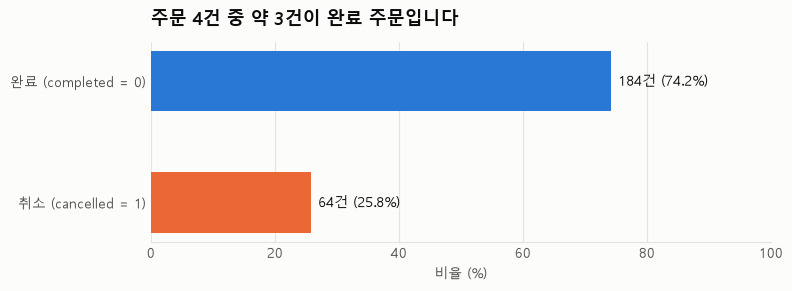

In [9]:
class_plot = target_dist.sort_values('is_cancelled')
labels = ['완료 (completed = 0)', '취소 (cancelled = 1)']

fig, ax = plt.subplots(figsize=(8, 2.6))
bars = ax.barh(labels, class_plot['ratio'] * 100, color=[BLUE, ORANGE], height=0.5)
for bar, count, ratio in zip(bars, class_plot['count'], class_plot['ratio']):
    ax.text(bar.get_width() + 1.2, bar.get_y() + bar.get_height() / 2,
            f'{count}건 ({ratio:.1%})', va='center', color=INK)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel('비율 (%)')
ax.set_title('주문 4건 중 약 3건이 완료 주문입니다', loc='left', pad=12)
clean_axes(ax, 'x')
save_figure(fig, 'step02_class_ratio.png')

## 답안 4. 클래스 비율

| 클래스 | 의미 | 개수 | 비율 |
| ---: | --- | ---: | ---: |
| 0 | completed | 184 | 74.19% |
| 1 | cancelled | 64 | 25.81% |

![클래스 비율](images/step02_class_ratio.png)

### 결과 관찰
완료 주문이 취소 주문의 약 2.9배로, 완료 주문 쪽으로 치우친 불균형 데이터입니다.

### 나의 해석과 판단
모든 주문을 완료로 예측해도 accuracy는 약 74%가 되지만 취소 주문은 한 건도 찾지 못합니다. 따라서 accuracy만으로 모델을 판단하지 않고 취소 클래스의 Precision, Recall, F1을 함께 확인해야 합니다.

## 6. train, validation, test 분리

모델과 임계값은 validation에서 선택하고, test는 최종 평가에 한 번만 사용합니다.

In [10]:
from src.classification import (
    split_train_validation_test,
    build_split_summary,
)

(
    X_train,
    X_valid,
    X_test,
    y_train,
    y_valid,
    y_test,
    features,
) = split_train_validation_test(
    model_data=model_data,
    numeric_features=numeric_features,
    categorical_features=categorical_features,
    random_state=42,
)

split_summary = build_split_summary(y_train, y_valid, y_test)

print('X_train:', X_train.shape)
print('X_valid:', X_valid.shape)
print('X_test:', X_test.shape)
display(split_summary)

X_train: (148, 10)
X_valid: (50, 10)
X_test: (50, 10)


,split,is_cancelled,class_label,count,ratio
0,train,0,completed,110,0.7432
1,train,1,cancelled,38,0.2568
2,validation,0,completed,37,0.7400
3,validation,1,cancelled,13,0.2600
4,test,0,completed,37,0.7400
5,test,1,cancelled,13,0.2600


## 7. 기준 모델과 학습 모델 비교

가장 많은 클래스만 예측하는 Dummy 모델을 기준으로 Logistic Regression과 Random Forest의 validation 성능을 비교합니다.

In [11]:
from src.classification import train_and_compare_on_validation

(
    models,
    validation_comparison,
    validation_predictions,
    validation_probabilities,
) = train_and_compare_on_validation(
    X_train=X_train,
    X_valid=X_valid,
    y_train=y_train,
    y_valid=y_valid,
    numeric_features=numeric_features,
    categorical_features=categorical_features,
    random_state=42,
)

validation_comparison

,model,evaluation_split,accuracy,precision,recall,f1
0,Logistic Regression,validation,0.64,0.352941,0.461538,0.40000
1,Random Forest,validation,0.66,0.300000,0.230769,0.26087
2,Dummy Most Frequent,validation,0.74,0.000000,0.000000,0.00000


In [12]:
fitted_preprocessor = models['Logistic Regression'].named_steps['preprocessor']
numeric_pipeline = fitted_preprocessor.named_transformers_['num']
categorical_pipeline = fitted_preprocessor.named_transformers_['cat']

pipeline_summary = pd.DataFrame([
    {'유형': '숫자형', 'feature 수': len(numeric_features), '전처리': ' → '.join(type(step).__name__ for _, step in numeric_pipeline.steps)},
    {'유형': '범주형', 'feature 수': len(categorical_features), '전처리': ' → '.join(type(step).__name__ for _, step in categorical_pipeline.steps)},
])
display(pipeline_summary)

position = numeric_features.index('days_since_signup')
train_median = X_train['days_since_signup'].median()
imputer_median = numeric_pipeline.named_steps['imputer'].statistics_[position]
assert train_median == imputer_median

print('OneHotEncoder handle_unknown:', categorical_pipeline.named_steps['onehot'].handle_unknown)
print('Train 중앙값:', train_median, '/ Pipeline 대체값:', imputer_median)

,유형,feature 수,전처리
0,숫자형,7,SimpleImputer → StandardScaler
1,범주형,3,SimpleImputer → OneHotEncoder


OneHotEncoder handle_unknown: ignore
Train 중앙값: 474.0 / Pipeline 대체값: 474.0


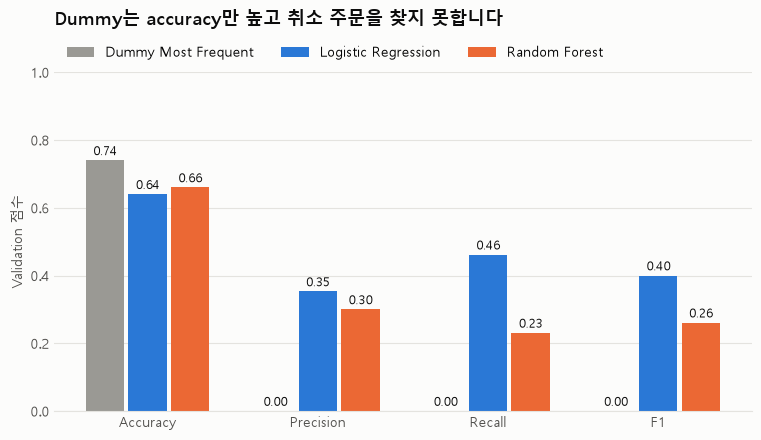

In [13]:
plot_order = ['Dummy Most Frequent', 'Logistic Regression', 'Random Forest']
plot_colors = [NEUTRAL, BLUE, ORANGE]
metrics = ['accuracy', 'precision', 'recall', 'f1']
metric_labels = ['Accuracy', 'Precision', 'Recall', 'F1']
comparison_plot = validation_comparison.set_index('model').loc[plot_order, metrics]

fig, ax = plt.subplots(figsize=(9, 4.4))
x = np.arange(len(metrics))
width = 0.25
for index, (model_name, color) in enumerate(zip(plot_order, plot_colors)):
    values = comparison_plot.loc[model_name].to_numpy()
    bars = ax.bar(x + (index - 1) * width, values, width * 0.9, color=color, label=model_name)
    ax.bar_label(bars, labels=[f'{value:.2f}' for value in values], padding=2, fontsize=8.5, color=INK)
ax.set_xticks(x, metric_labels)
ax.set_ylim(0, 1)
ax.set_ylabel('Validation 점수')
ax.set_title('Dummy는 accuracy만 높고 취소 주문을 찾지 못합니다', loc='left', pad=34)
ax.legend(ncol=3, frameon=False, loc='lower left', bbox_to_anchor=(0, 1.0))
clean_axes(ax)
save_figure(fig, 'step03_baseline.png')

## 8. validation에서 모델과 임계값 선택

Dummy 모델은 기준선이므로 실제 선택 후보에서는 제외합니다. validation의 f1-score를 우선하고 recall과 precision을 함께 확인합니다.

In [14]:
from src.classification import (
    build_selection_summary,
    choose_threshold,
    select_validation_model,
    threshold_metrics,
)
from sklearn.metrics import confusion_matrix

selected_model_name = select_validation_model(validation_comparison)
selected_model = models[selected_model_name]
validation_proba = validation_probabilities[selected_model_name]

threshold_df = threshold_metrics(y_valid, validation_proba)
selected_threshold = choose_threshold(threshold_df)

rows = []
for threshold in threshold_df['threshold']:
    tn, fp, fn, tp = confusion_matrix(y_valid, (validation_proba >= threshold).astype(int), labels=[0, 1]).ravel()
    rows.append({'threshold': threshold, 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp})
threshold_detail = threshold_df.merge(pd.DataFrame(rows), on='threshold')

print('선택 모델:', selected_model_name)
print('선택 임계값:', selected_threshold)
display(threshold_detail.round(3))

선택 모델: Logistic Regression
선택 임계값: 0.3


,threshold,accuracy,precision,recall,f1,TN,FP,FN,TP
0,0.20,0.30,0.261,0.923,0.407,3,34,1,12
1,0.25,0.40,0.293,0.923,0.444,8,29,1,12
2,0.30,0.46,0.306,0.846,0.449,12,25,2,11
3,0.35,0.50,0.286,0.615,0.390,17,20,5,8
4,0.40,0.56,0.304,0.538,0.389,21,16,6,7
5,0.45,0.54,0.273,0.462,0.343,21,16,7,6
6,0.50,0.64,0.353,0.462,0.400,26,11,7,6
7,0.55,0.68,0.400,0.462,0.429,28,9,7,6
8,0.60,0.68,0.385,0.385,0.385,29,8,8,5
9,0.65,0.70,0.417,0.385,0.400,30,7,8,5


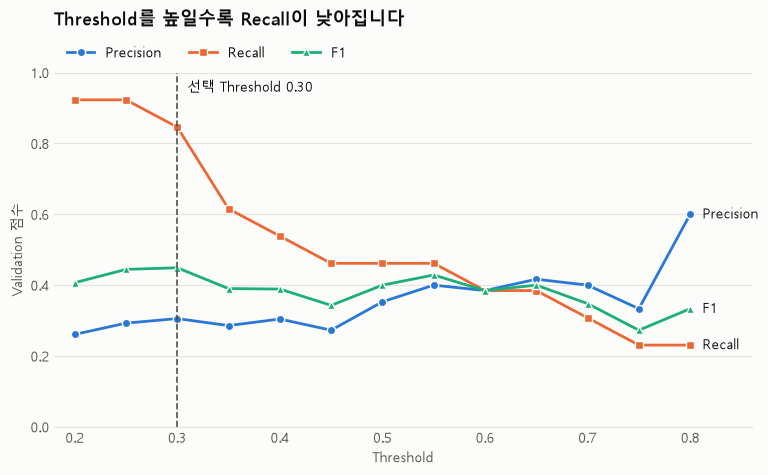

In [15]:
fig, ax = plt.subplots(figsize=(9, 4.6))
series = [('precision', 'Precision', BLUE, 'o'), ('recall', 'Recall', ORANGE, 's'), ('f1', 'F1', AQUA, '^')]
for column, label, color, marker in series:
    ax.plot(threshold_df['threshold'], threshold_df[column], color=color, linewidth=2,
            marker=marker, markersize=6, markeredgecolor=SURFACE, label=label)
    ax.annotate(label, (threshold_df['threshold'].iloc[-1], threshold_df[column].iloc[-1]),
                xytext=(9, 0), textcoords='offset points', va='center', color=INK)

ax.axvline(selected_threshold, color=MUTED, linestyle='--', linewidth=1.2)
ax.annotate(f'선택 Threshold {selected_threshold:.2f}', (selected_threshold, 0.98),
            xytext=(7, 0), textcoords='offset points', va='top', color=INK)
ax.set_xlim(0.18, 0.86)
ax.set_ylim(0, 1)
ax.set_xlabel('Threshold')
ax.set_ylabel('Validation 점수')
ax.set_title('Threshold를 높일수록 Recall이 낮아집니다', loc='left', pad=34)
ax.legend(ncol=3, frameon=False, loc='lower left', bbox_to_anchor=(0, 1.0))
clean_axes(ax)
save_figure(fig, 'step05_threshold.png')

In [16]:
FROZEN_MODEL_NAME = selected_model_name
FROZEN_THRESHOLD = selected_threshold

selection_summary = build_selection_summary(
    selected_model_name=FROZEN_MODEL_NAME,
    selected_threshold=FROZEN_THRESHOLD,
    validation_comparison=validation_comparison,
    threshold_df=threshold_df,
)
frozen_validation_metrics = threshold_df.loc[np.isclose(threshold_df['threshold'], FROZEN_THRESHOLD)]

display(selection_summary)
display(frozen_validation_metrics.round(3))

,selection_item,value,selected_on,criterion
0,model,Logistic Regression,validation,f1 → recall → precision
1,threshold,0.3,validation,f1 → recall → precision → lower threshold


,threshold,accuracy,precision,recall,f1
2,0.3,0.46,0.306,0.846,0.449


## 답안 5. Dummy Baseline과 Validation 모델 비교

기본 Threshold 0.5 기준의 Validation 결과입니다.

| 모델 | Accuracy | Precision | Recall | F1 |
| --- | ---: | ---: | ---: | ---: |
| Dummy Most Frequent | 0.740 | 0.000 | 0.000 | 0.000 |
| Logistic Regression | 0.640 | 0.353 | 0.462 | 0.400 |
| Random Forest | 0.660 | 0.300 | 0.231 | 0.261 |

- Validation에서 선택한 모델: **Logistic Regression**
![Baseline 비교](images/step03_baseline.png)

### 결과 관찰
Accuracy는 Dummy가 0.740으로 가장 높지만 취소 주문을 한 건도 찾지 못했습니다. Logistic Regression은 비베이스라인 후보 중 F1이 가장 높습니다.

### 나의 해석과 판단
선택한 모델은 Accuracy가 Dummy보다 0.100 낮지만, 취소 주문 13건 중 6건을 찾아 Recall이 0.000에서 0.462로 높아졌습니다. 이번 과제의 목적이 취소 주문을 찾아내는 것이므로 F1, Recall, Precision 순서의 선택 규칙으로 Logistic Regression을 골랐습니다.

### 한계와 추가 확인 사항
Validation은 50건이고 그중 취소 주문은 13건뿐이어서 한 건만 달라져도 Recall이 약 7.7%p 변합니다. 두 모델의 차이가 안정적인지는 더 많은 데이터로 확인해야 합니다.

## 답안 6. Train / Validation / Test 역할

| Split | 역할 | 클래스 0 건수 | 클래스 1 건수 |
| --- | --- | ---: | ---: |
| Train | 모델 학습 | 110 | 38 |
| Validation | 모델·Threshold 선택 | 37 | 13 |
| Test | 선택 이후 최종 평가 | 37 | 13 |

### 나의 해석과 판단
Test로 모델이나 Threshold를 고르면 그 Test에 맞춘 선택이 되어 성능이 실제보다 좋게 보입니다. 그러면 처음 보는 데이터에서의 성능을 추정한다는 Test의 역할이 사라집니다.

### 교육용 random split의 한계
random split은 미래 주문이 Train에 섞일 수 있어 실제 운영 상황과 다릅니다. 운영 전에는 과거 기간으로 학습하고 이후 기간으로 평가하는 시간 순서 검증과 out-of-time 평가를 추가해야 합니다.

## 답안 7. Validation 성능과 우선 지표

선택 모델에 Threshold 0.30을 적용한 Validation 결과입니다.

- Accuracy: 0.460
- Precision: 0.306
- Recall: 0.846
- F1: 0.449

### 내가 가장 중요하게 본 지표
모델과 Threshold 선택에는 **F1**을 기준으로 사용했고, 결과 해석에서는 **Recall**을 가장 중요하게 보았습니다.

### 그 이유
취소 위험 주문을 놓치면 사전 대응 기회 자체가 사라진다고 **가정**했기 때문입니다. 다만 Recall만 높이면 대부분의 주문을 취소 위험으로 표시하게 되므로 Precision과의 균형을 F1로 함께 확인했습니다. 실제 FP/FN 비용 정보가 없으므로 이 우선순위는 확정이 아닌 가정입니다.

## 답안 8. Threshold 비교

| Threshold | Precision | Recall | F1 | FP / FN | 예상 특징 |
| ---: | ---: | ---: | ---: | ---: | --- |
| 0.25 | 0.293 | 0.923 | 0.444 | 29 / 1 | 놓치는 취소는 가장 적지만 오탐이 많음 |
| **0.30** | **0.306** | **0.846** | **0.449** | **25 / 2** | Validation F1이 가장 높음 |
| 0.50 | 0.353 | 0.462 | 0.400 | 11 / 7 | 오탐은 줄지만 취소 주문을 절반 이상 놓침 |
| 0.80 | 0.600 | 0.231 | 0.333 | 2 / 10 | 표시한 주문의 정확도는 높지만 대부분의 취소를 놓침 |


![Threshold 비교](images/step05_threshold.png)

### 내가 선택한 Threshold
**0.30**

### 선택 이유
비교한 13개 Threshold 중 Validation F1이 0.449로 가장 높고, 취소 주문 13건 중 11건을 찾을 수 있습니다. 대신 완료 주문 37건 중 25건을 취소 위험으로 잘못 표시하므로 오탐 부담이 큽니다.

### 나의 해석과 판단
Final Test를 보면서 Threshold를 정하면 Test 결과가 선택에 반영되어 최종 성능을 객관적으로 평가할 수 없습니다. 그래서 모델과 Threshold를 모두 Validation에서 고정한 뒤 Final Test를 실행했습니다.

## 9. test 데이터 최종 평가

이제 선택이 끝났으므로 test 데이터에서 최종 성능을 한 번 확인합니다.

In [17]:
assert selected_model_name == FROZEN_MODEL_NAME
assert selected_threshold == FROZEN_THRESHOLD

from src.classification import (
    final_test_evaluation,
    confusion_matrix_dataframe,
    classification_report_dataframe,
)

y_pred_test, y_proba_test, test_metrics = final_test_evaluation(
    selected_model,
    X_test,
    y_test,
    threshold=selected_threshold,
)

confusion_df = confusion_matrix_dataframe(y_test, y_pred_test)
classification_report_df = classification_report_dataframe(y_test, y_pred_test)

display(test_metrics)
display(confusion_df)
display(classification_report_df)

,evaluation_split,threshold,selection_status,accuracy,precision,recall,f1
0,test,0.3,frozen_before_test,0.42,0.289474,0.846154,0.431373


,pred_completed,pred_cancelled
actual_completed,10,27
actual_cancelled,2,11


,label,precision,recall,f1-score,support
0,completed,0.833333,0.270270,0.408163,37.00
1,cancelled,0.289474,0.846154,0.431373,13.00
2,accuracy,0.420000,0.420000,0.420000,0.42
3,macro avg,0.561404,0.558212,0.419768,50.00
4,weighted avg,0.691930,0.420000,0.414198,50.00


혼동행렬은 다음처럼 읽습니다.

| 구분 | 의미 |
|---|---|
| True Negative | 실제 완료 주문을 완료로 예측 |
| False Positive | 실제 완료 주문을 취소로 잘못 예측 |
| False Negative | 실제 취소 주문을 완료로 잘못 예측 |
| True Positive | 실제 취소 주문을 취소로 예측 |

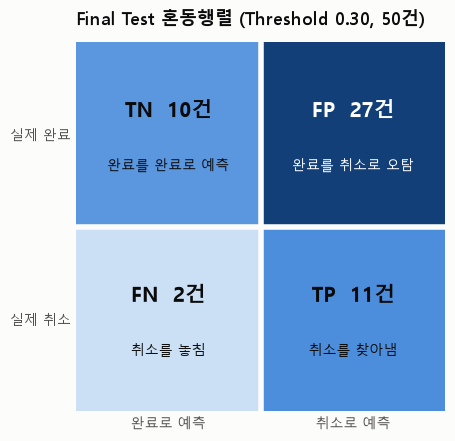

In [18]:
matrix = confusion_df.to_numpy()
cell_names = np.array([['TN', 'FP'], ['FN', 'TP']])
cell_meaning = np.array([['완료를 완료로 예측', '완료를 취소로 오탐'], ['취소를 놓침', '취소를 찾아냄']])
blue_scale = LinearSegmentedColormap.from_list('blue_scale', ['#e6f0fb', BLUE, '#123f78'])

fig, ax = plt.subplots(figsize=(6.6, 4.8))
ax.imshow(matrix, cmap=blue_scale, vmin=0, vmax=matrix.max())
for row in range(2):
    for column in range(2):
        text_color = 'white' if matrix[row, column] >= matrix.max() * 0.45 else INK
        ax.text(column, row - 0.13, f'{cell_names[row, column]}  {matrix[row, column]}건',
                ha='center', va='center', fontsize=15, fontweight='bold', color=text_color)
        ax.text(column, row + 0.17, cell_meaning[row, column], ha='center', va='center', fontsize=10, color=text_color)
ax.set_xticks([0, 1], ['완료로 예측', '취소로 예측'])
ax.set_yticks([0, 1], ['실제 완료', '실제 취소'])
ax.set_xticks([0.5], minor=True)
ax.set_yticks([0.5], minor=True)
ax.grid(which='minor', color=SURFACE, linewidth=4)
ax.tick_params(which='both', length=0)
ax.spines[:].set_visible(False)
ax.set_title(f'Final Test 혼동행렬 (Threshold {FROZEN_THRESHOLD:.2f}, 50건)', loc='left', pad=12)
save_figure(fig, 'step06_confusion_matrix.png')

In [19]:
from src.classification import evaluate_classification_predictions

reference_predictions = {
    'Dummy Most Frequent (모두 완료)': models['Dummy Most Frequent'].predict(X_test),
    '모두 취소로 예측': np.ones(len(y_test), dtype=int),
    f'{FROZEN_MODEL_NAME} (Threshold {FROZEN_THRESHOLD:.2f})': y_pred_test,
}
test_reference = pd.DataFrame([
    {'기준': name, '취소로 표시한 주문': int(pred.sum()), **evaluate_classification_predictions(y_test, pred)}
    for name, pred in reference_predictions.items()
])
print('이 표는 해석용 비교이며 모델과 Threshold 선택에는 사용하지 않습니다.')
display(test_reference.round(3))

이 표는 해석용 비교이며 모델과 Threshold 선택에는 사용하지 않습니다.


,기준,취소로 표시한 주문,accuracy,precision,recall,f1
0,Dummy Most Frequent (모두 완료),0,0.74,0.000,0.000,0.000
1,모두 취소로 예측,50,0.26,0.260,1.000,0.413
2,Logistic Regression (Threshold 0.30),38,0.42,0.289,0.846,0.431


## 답안 9. FP/FN 해석

- FP 의미: 실제 완료된 주문을 취소 위험으로 예측한 경우 (27건)
- FN 의미: 실제 취소된 주문을 완료로 예측한 경우 (2건)
- 현재 목적에서 더 부담스러울 수 있는 오류: 사전 대응 기회를 잃는 **FN**이라고 가정했습니다. 다만 현재 모델은 FP가 27건으로 매우 많아, 실제 대응 비용이 크다면 FP가 더 큰 문제가 될 수 있습니다.
- 그 판단에 추가로 필요한 업무 정보: 취소 1건당 손실액, 건당 대응 비용과 대응 성공률, 하루 처리 가능 건수, 불필요한 연락이 고객 경험에 미치는 영향


![Confusion Matrix](images/step06_confusion_matrix.png)

### 업무·분석적 의미
FP가 많으면 정상 주문에도 확인 연락이나 쿠폰 같은 대응 비용이 쓰이고 고객이 불편을 느낄 수 있습니다. FN이 많으면 취소될 주문에 대응하지 못해 매출과 재고·배송 준비 비용에서 손실이 생길 수 있습니다. 이 모델을 그대로 쓰면 Test 주문 50건 중 38건(76%)이 대응 대상이 되어 업무 우선순위를 좁혀 주는 효과가 작습니다.

### 한계와 추가 확인 사항
수업 데이터에는 비용 정보가 없으므로 위 내용은 가정이며 실제 업무 비용을 확정한 것이 아닙니다. Test의 취소 주문이 13건뿐이라 FN 수치의 안정성도 더 큰 데이터로 확인해야 합니다.

## 답안 10. Final Test

- 고정한 모델: Logistic Regression
- 고정한 Threshold: 0.30
- Accuracy: 0.420
- Precision: 0.289
- Recall: 0.846
- F1: 0.431
- Validation 대비 변화: Accuracy -0.040, Precision -0.016, Recall 0.000, F1 -0.018

### 결과 관찰
취소 주문 13건 중 11건을 찾았지만 완료 주문 37건 중 27건을 취소로 잘못 표시했습니다. Accuracy 0.420은 모두 완료로 예측하는 Dummy의 0.740보다 낮습니다. Precision 0.289도 Test의 실제 취소 비율 0.260과 큰 차이가 없고, F1 0.431은 모든 주문을 취소로 예측할 때의 0.413보다 0.019 높은 수준입니다.

### 나의 해석과 판단
Validation과 Test의 지표가 비슷해 심한 과적합 징후는 보이지 않습니다. 하지만 성능 자체가 단순 기준과 거의 차이가 없어, 취소 주문을 구분하는 능력이 일반화되었다고 판단하기 어렵습니다. 높은 Recall은 모델의 구분력보다 낮은 Threshold로 대부분의 주문을 취소로 표시한 결과에 가깝습니다.

### 선택 보호 확인
- [x] Test 결과를 보기 전에 모델을 고정했습니다.
- [x] Test 결과를 보기 전에 Threshold를 고정했습니다.
- [x] Test 결과를 본 뒤 같은 Test를 이용해 선택을 바꾸지 않았습니다.

> 모델과 Threshold는 Validation 규칙으로만 정했습니다. 다만 날짜 오류 45건의 전처리 방식을 정할 때 Test 지표를 확인한 이력이 있어 아래 13번 프롬프트의 'LLM 코드 검토 결과'에 공개했습니다.

## 10. 개인정보를 제외한 예측 결과 생성

고객명, 이메일, 주소 같은 불필요한 식별정보는 결과 파일에 저장하지 않습니다.

In [20]:
from src.classification import create_prediction_result, public_prediction_result

prediction_result_internal = create_prediction_result(
    source_index=X_test.index,
    y_test=y_test,
    y_pred=y_pred_test,
    y_proba=y_proba_test,
    model_name=selected_model_name,
    threshold=selected_threshold,
)
prediction_result = public_prediction_result(prediction_result_internal)

public_forbidden = {'source_index', 'order_id', 'customer_id', 'product_id', 'name', 'email', 'phone', 'address'}
public_leak = sorted(public_forbidden & set(prediction_result.columns))
assert not public_leak, f'공개 결과에 식별자 포함: {public_leak}'

print('공개 Prediction 컬럼:', prediction_result.columns.tolist())
print('공개 결과의 금지 컬럼:', len(public_leak), '건')
prediction_result.head()

공개 Prediction 컬럼: ['record_id', 'actual_is_cancelled', 'predicted_is_cancelled', 'cancel_probability', 'model', 'threshold']
공개 결과의 금지 컬럼: 0 건


,record_id,actual_is_cancelled,predicted_is_cancelled,cancel_probability,model,threshold
0,test_0001,0,1,0.580276,Logistic Regression,0.3
1,test_0002,0,1,0.514056,Logistic Regression,0.3
2,test_0003,0,1,0.417463,Logistic Regression,0.3
3,test_0004,0,1,0.755099,Logistic Regression,0.3
4,test_0005,0,1,0.867781,Logistic Regression,0.3


## 답안 11. Internal / Public 결과 구분

### 공개 Prediction 컬럼

```text
record_id
actual_is_cancelled
predicted_is_cancelled
cancel_probability
model
threshold
```

### 공개 결과에 없어야 할 컬럼

```text
source_index
order_id
customer_id
product_id
```

### 결과 관찰
공개 결과에는 위 6개 컬럼만 있고 금지 컬럼은 0건입니다. `record_id`는 `test_0001`처럼 새로 부여한 번호여서 원본 주문이나 고객과 연결되지 않습니다.

### 나의 해석과 판단
내부 오류 분석에서는 어떤 주문이 틀렸는지 추적해야 하므로 원본과 연결되는 정보가 필요합니다. 하지만 이 정보가 공개되면 개별 주문이나 고객이 특정될 수 있습니다. 성능 검증과 공개 범위 검토는 별개의 문제이므로 내부 자료와 공개 결과를 분리했습니다.

## 11. LLM 코드 검토 체크리스트

In [21]:
from src.classification import build_classification_checklist

classification_checklist = build_classification_checklist()
classification_checklist

,check_item,status
0,completed와 cancelled만 사용해 이진 타깃을 만들었는가?,□
1,refunded 등 다른 상태를 0 클래스에 섞지 않았는가?,□
2,예측 시점과 feature 가용성 가정을 설명할 수 있는가?,□
3,line_total = quantity × unit_price를 검증했는가?,□
4,병합에 validate를 사용하고 미매칭 0건을 확인했는가?,□
5,"order_status, target, ID, 사후 정보를 feature에서 제외했는가?",□
6,"train, validation, test를 분리했는가?",□
7,모델과 threshold는 validation에서 선택했는가?,□
8,모델과 threshold를 고정한 뒤 test를 한 번만 사용했는가?,□
9,Dummy 기준 모델과 비교했는가?,□


## 12. 전체 파이프라인 실행과 산출물 저장

위 과정을 한 번에 다시 실행해 CSV와 Markdown 보고서를 생성합니다.

In [22]:
from src.classification import run_classification_analysis

classification_result = run_classification_analysis(
    processed_dir=PROCESSED_DIR,
    report_dir=REPORT_DIR,
    random_state=42,
)

print('선택 모델:', classification_result['selected_model_name'])
print('선택 임계값:', classification_result['selected_threshold'])
display(classification_result['test_metrics'])

for name, path in classification_result['output_paths'].items():
    print(name, path, 'OK' if path.exists() else 'MISSING')

선택 모델: Logistic Regression
선택 임계값: 0.3


,evaluation_split,threshold,selection_status,accuracy,precision,recall,f1
0,test,0.3,frozen_before_test,0.42,0.289474,0.846154,0.431373


model_data_internal C:\dev\llm-data-analysis-study\reports\ch10_classification_model_data_internal.csv OK
target_distribution C:\dev\llm-data-analysis-study\reports\ch10_target_distribution.csv OK
feature_audit C:\dev\llm-data-analysis-study\reports\ch10_feature_audit.csv OK
merge_checks C:\dev\llm-data-analysis-study\reports\ch10_merge_checks.csv OK
data_quality_checks C:\dev\llm-data-analysis-study\reports\ch10_data_quality_checks.csv OK
split_summary C:\dev\llm-data-analysis-study\reports\ch10_split_summary.csv OK
validation_comparison C:\dev\llm-data-analysis-study\reports\ch10_validation_model_comparison.csv OK
threshold_metrics C:\dev\llm-data-analysis-study\reports\ch10_validation_threshold_metrics.csv OK
test_metrics C:\dev\llm-data-analysis-study\reports\ch10_test_metrics.csv OK
predictions_internal C:\dev\llm-data-analysis-study\reports\ch10_classification_predictions_internal.csv OK
predictions C:\dev\llm-data-analysis-study\reports\ch10_classification_predictions.csv OK
con

In [23]:
scripts = ['scripts/prepare_ch10_data.py', 'scripts/run_classification_analysis.py']
script_env = {**os.environ, 'PYTHONIOENCODING': 'utf-8'}

for script in scripts:
    completed = subprocess.run(
        [sys.executable, script],
        cwd=PROJECT_ROOT,
        env=script_env,
        capture_output=True,
        text=True,
        encoding='utf-8',
    )
    print(f'===== {script} (종료 코드 {completed.returncode}) =====')
    print(completed.stdout)
    if completed.returncode != 0:
        raise RuntimeError(completed.stderr)

===== scripts/prepare_ch10_data.py (종료 코드 0) =====
Chapter10 모델링 입력 준비 완료
입력 Raw 경로: C:\dev\llm-data-analysis-study\data\raw

[관계 검증]
                                               check  invalid_count
  orders.customer_id exists in customers.customer_id              0
      order_items.order_id exists in orders.order_id              0
order_items.product_id exists in products.product_id              0

[저장된 processed 파일]
- C:\dev\llm-data-analysis-study\data\processed\customers_clean.csv
- C:\dev\llm-data-analysis-study\data\processed\products_clean.csv
- C:\dev\llm-data-analysis-study\data\processed\orders_clean.csv
- C:\dev\llm-data-analysis-study\data\processed\order_items_clean.csv



===== scripts/run_classification_analysis.py (종료 코드 0) =====
Chapter10 분류 분석 완료

[모델링 데이터]
(248, 16)

[타깃 분포]
 is_cancelled class_label  count  ratio
            0   completed    184 0.7419
            1   cancelled     64 0.2581

[Feature Audit]
           column  selected            role                 reason
              age      True allowed_feature 교육용 예측 시점에 사용 가능하다고 가정
       item_count      True allowed_feature 교육용 예측 시점에 사용 가능하다고 가정
   total_quantity      True allowed_feature 교육용 예측 시점에 사용 가능하다고 가정
     order_amount      True allowed_feature 교육용 예측 시점에 사용 가능하다고 가정
      order_month      True allowed_feature 교육용 예측 시점에 사용 가능하다고 가정
  order_dayofweek      True allowed_feature 교육용 예측 시점에 사용 가능하다고 가정
days_since_signup      True allowed_feature 교육용 예측 시점에 사용 가능하다고 가정
           gender      True allowed_feature 교육용 예측 시점에 사용 가능하다고 가정
             city      True allowed_feature 교육용 예측 시점에 사용 가능하다고 가정
   payment_method      True allowed_feature 교육용 예측 시점에 사용 가능하다고 가정
    cancel_reaso

In [24]:
script_metrics = pd.read_csv(REPORT_DIR / 'ch10_test_metrics.csv').iloc[0]
script_predictions = pd.read_csv(REPORT_DIR / 'ch10_classification_predictions.csv')
notebook_metrics = test_metrics.iloc[0]

consistency = pd.DataFrame([
    {'항목': '선택 모델', 'Notebook': selected_model_name, 'Script': script_predictions['model'].iloc[0]},
    {'항목': 'Threshold', 'Notebook': selected_threshold, 'Script': float(script_metrics['threshold'])},
    *[
        {'항목': metric, 'Notebook': round(float(notebook_metrics[metric]), 6), 'Script': round(float(script_metrics[metric]), 6)}
        for metric in ['accuracy', 'precision', 'recall', 'f1']
    ],
])
consistency['일치'] = consistency['Notebook'] == consistency['Script']
assert consistency['일치'].all()
display(consistency)

evidence_files = [
    'ch10_target_distribution.csv', 'ch10_feature_audit.csv', 'ch10_merge_checks.csv',
    'ch10_data_quality_checks.csv', 'ch10_split_summary.csv', 'ch10_validation_model_comparison.csv',
    'ch10_validation_threshold_metrics.csv', 'ch10_test_metrics.csv', 'ch10_classification_predictions.csv',
    'ch10_confusion_matrix.csv', 'ch10_classification_validation.csv', 'ch10_classification_summary.md',
]
evidence_status = pd.DataFrame({
    'file': evidence_files,
    'exists': [(REPORT_DIR / name).exists() for name in evidence_files],
})
assert evidence_status['exists'].all()
display(evidence_status)
display(classification_result['validation'])

,항목,Notebook,Script,일치
0,선택 모델,Logistic Regression,Logistic Regression,True
1,Threshold,0.3,0.3,True
2,accuracy,0.42,0.42,True
3,precision,0.289474,0.289474,True
4,recall,0.846154,0.846154,True
5,f1,0.431373,0.431373,True


,file,exists
0,ch10_target_distribution.csv,True
1,ch10_feature_audit.csv,True
2,ch10_merge_checks.csv,True
3,ch10_data_quality_checks.csv,True
4,ch10_split_summary.csv,True
5,ch10_validation_model_comparison.csv,True
6,ch10_validation_threshold_metrics.csv,True
7,ch10_test_metrics.csv,True
8,ch10_classification_predictions.csv,True
9,ch10_confusion_matrix.csv,True


,check,value,status
0,target_exactly_completed_cancelled,"[0, 1]",PASS
1,forbidden_feature_overlap,0,PASS
2,merge_rows_and_matches,True,PASS
3,all_splits_have_both_classes,True,PASS
4,model_selected_on_validation,True,PASS
5,threshold_selected_on_validation,True,PASS
6,public_prediction_identifier_columns,none,PASS


## 답안 12. Validation Evidence

다음 Evidence를 모두 확인했습니다.

- [x] `ch10_target_distribution.csv`
- [x] `ch10_feature_audit.csv`
- [x] `ch10_merge_checks.csv`
- [x] `ch10_data_quality_checks.csv`
- [x] `ch10_split_summary.csv`
- [x] `ch10_validation_model_comparison.csv`
- [x] `ch10_validation_threshold_metrics.csv`
- [x] `ch10_test_metrics.csv`
- [x] `ch10_confusion_matrix.csv`
- [x] `ch10_classification_validation.csv`

### 자동 Validation 결과
타깃 범위, 금지 feature, 병합, split의 클래스 구성, Validation 기반 모델·Threshold 선택, 공개 결과 식별자까지 7개 항목이 모두 PASS입니다. Notebook과 Script의 선택 모델, Threshold, Final Test 지표도 일치합니다.

### 자동 PASS가 의미하지 않는 것
자동 PASS는 코드가 정해진 분석 규칙을 지켰다는 뜻입니다. 모델 성능이 충분하다거나 운영에 적합하다는 뜻은 아니며, 고객 집단 간 공정성, 시간에 따른 성능 변화, 실제 업무 비용 대비 효과도 보장하지 않습니다. 실제로 이번 모델은 7개 항목을 모두 통과했지만 성능은 사용하기에 부족합니다.

## 13. LLM 검토 프롬프트 예시

```text
온라인 쇼핑몰 주문 취소 분류 코드를 검토해 주세요.

타깃 기준:
- completed=0
- cancelled=1
- refunded와 기타 상태는 제외

검토 항목:
1. order_status와 is_cancelled가 feature에서 제외되었는가?
2. 병합에 validate와 indicator가 사용되었는가?
3. train, validation, test가 분리되었는가?
4. 모델과 임계값은 validation에서 선택했는가?
5. test는 최종 평가에 한 번만 사용했는가?
6. Dummy 기준 모델보다 나은가?
7. accuracy, precision, recall, f1을 함께 확인했는가?
8. 예측 결과에 개인정보가 포함되지 않았는가?
9. 모델 결과를 취소 원인으로 단정하지 않았는가?

필수 수정과 권장 개선을 구분해 설명해 주세요.
```

---

LLM 코드 검토 결과 



| 번호 | 검토 항목 | 판정 | 근거 |
| ---: | --- | --- | --- |
| 1 | `order_status`, `is_cancelled` 제외 | 통과 | 입력 feature와 금지 feature의 겹침 0건 |
| 2 | 병합에 `validate`, `indicator` 사용 | 통과 | 두 병합 모두 행 수 유지, 미매칭 0건 |
| 3 | train, validation, test 분리 | 통과 | 148 / 50 / 50건으로 분리, 중복 행 없음 |
| 4 | 모델과 임계값을 validation에서 선택 | 통과 | Logistic Regression, Threshold 0.30을 Test 전에 고정 |
| 5 | test를 최종 평가에 한 번만 사용 | **조건부 통과** | 모델·Threshold 선택에는 쓰지 않았지만, 아래 필수 수정 1의 확인 이력이 있음 |
| 6 | Dummy 기준 모델보다 나은가 | **조건부 통과** | Test F1은 0.000 → 0.431로 개선, Accuracy는 0.740 → 0.420으로 하락 |
| 7 | accuracy, precision, recall, f1 함께 확인 | 통과 | Validation과 Final Test에서 4개 지표 모두 확인 |
| 8 | 예측 결과에 개인정보 미포함 | 통과 | 공개 결과에 식별자 컬럼과 고객명 값 없음 |
| 9 | 모델 결과를 취소 원인으로 단정하지 않음 | 통과 | 답안 13에서 예측 패턴과 원인 주장을 구분 |

#### 필수 수정
1. **Final Test 확인 이력 공개 (이 답안에 반영):** 가입일보다 빠른 주문 45건의 처리 방식을 정할 때, 결측 처리안과 행 제외안의 Test 지표를 모두 확인했습니다. 결측 처리안은 Test Accuracy가 더 낮았지만(0.420, 행 제외안 0.683), 주문 자체는 유효하다는 데이터 기준으로 선택했습니다. 그래도 Test를 본 뒤 내린 전처리 결정이므로, 현재 Final Test는 완전히 독립적인 평가로 볼 수 없습니다. 엄밀한 성능 평가에는 새로운 holdout 데이터가 필요합니다.
2. **실행 스크립트 경로 오류 (해결):** `python scripts/run_classification_analysis.py`를 실행하면 `No module named 'src'` 오류가 발생했습니다. 스크립트에 프로젝트 루트 경로 설정을 추가해 가이드 명령어 그대로 실행되도록 수정했습니다.

#### 권장 개선
1. `days_since_signup`이 결측이었는지를 나타내는 feature를 추가해 비교합니다.
2. `order_month`, `order_dayofweek`는 크기 순서가 없는 주기형 값이므로 범주형 또는 주기형 인코딩을 비교합니다.
3. `class_weight="balanced"`를 쓴 모델의 확률은 실제 취소 확률과 다를 수 있으므로 확률 보정을 검토합니다.
4. 데이터가 적으므로 Train 안에서 교차검증을 사용해 모델 비교의 안정성을 확인합니다.

#### 나의 판단
코드 계약은 대부분 지켜졌지만 Final Test 확인 이력과 낮은 성능을 고려하면 **현재 사용 보류** 판단을 유지합니다.

In [25]:
import inspect

from src.classification import _checked_left_merge

merge_source = inspect.getsource(_checked_left_merge)
customer_names = set(customers['name'].astype(str))
public_values = set(prediction_result.astype(str).to_numpy().ravel())
reference = test_reference.set_index('기준')
dummy_result = reference.iloc[0]
model_result = reference.iloc[2]

review_checks = [
    (1, 'order_status, is_cancelled 제외', not ({'order_status', 'is_cancelled'} & set(features)), '입력 feature와 겹침 0건'),
    (2, '병합 validate, indicator 사용', 'validate=validate' in merge_source and 'indicator=True' in merge_source, '공통 병합 함수에서 두 옵션 사용'),
    (3, 'train, validation, test 분리', not (set(X_train.index) & set(X_valid.index) or set(X_train.index) & set(X_test.index) or set(X_valid.index) & set(X_test.index)), f'{len(X_train)} / {len(X_valid)} / {len(X_test)}건, 중복 0건'),
    (4, '모델, 임계값 validation 선택', selected_model_name == FROZEN_MODEL_NAME and selected_threshold == FROZEN_THRESHOLD, f'{FROZEN_MODEL_NAME}, {FROZEN_THRESHOLD:.2f}'),
    (7, '4개 지표 함께 확인', {'accuracy', 'precision', 'recall', 'f1'} <= set(test_metrics.columns), 'accuracy, precision, recall, f1'),
    (8, '예측 결과 개인정보 제외', not public_leak and not (customer_names & public_values), '금지 컬럼 0건, 고객명 값 0건'),
]
review = pd.DataFrame(review_checks, columns=['번호', '검토 항목', '통과', '근거'])
assert review['통과'].all()

print('Dummy 대비 Test F1:', round(dummy_result['f1'], 3), '→', round(model_result['f1'], 3))
print('Dummy 대비 Test Accuracy:', round(dummy_result['accuracy'], 3), '→', round(model_result['accuracy'], 3))
display(review)

Dummy 대비 Test F1: 0.0 → 0.431
Dummy 대비 Test Accuracy: 0.74 → 0.42


,번호,검토 항목,통과,근거
0,1,"order_status, is_cancelled 제외",True,입력 feature와 겹침 0건
1,2,"병합 validate, indicator 사용",True,공통 병합 함수에서 두 옵션 사용
2,3,"train, validation, test 분리",True,"148 / 50 / 50건, 중복 0건"
3,4,"모델, 임계값 validation 선택",True,"Logistic Regression, 0.30"
4,7,4개 지표 함께 확인,True,"accuracy, precision, recall, f1"
5,8,예측 결과 개인정보 제외,True,"금지 컬럼 0건, 고객명 값 0건"


## 답안 13. 최종 사용 판단

- [ ] 참고용 사용 가능
- [ ] 추가 검증 후 사용 가능
- [x] 현재 사용 보류

### 판단 근거
1. **Baseline 대비 개선 부족:** 클래스 비율은 완료 74.2%, 취소 25.8%입니다. Final Test Accuracy 0.420은 Dummy 0.740보다 낮고, F1 0.431은 모든 주문을 취소로 예측한 0.413과 거의 같습니다.
2. **오탐 부담:** Threshold 0.30은 Validation F1 기준으로 골랐고 Recall은 0.846이지만 Precision은 0.289입니다. Test 50건 중 38건을 취소 위험으로 표시해 FP가 27건 발생했습니다. FN을 더 중요하게 보는 가정을 적용해도 대응 대상이 지나치게 많습니다.
3. **검증 근거 부족:** Test의 취소 주문은 13건뿐이고 random split만 사용했으며, `days_since_signup`의 18.1%는 날짜 오류로 결측 처리했습니다. 또한 `scripts/generate_sample_data.py`는 `order_status`를 고객·주문 특징과 무관하게 무작위로 배정하므로, 이 샘플 데이터에서는 높은 구분력을 기대하기 어렵습니다. 공개 결과의 식별자 제거는 확인했지만, 이는 성능 부족을 보완하지 못합니다.

### 현재 모델의 가장 큰 위험
취소 위험을 구분하는 능력이 낮은데도 Recall 0.846만 보고 효과적인 모델로 오해할 수 있다는 점입니다. 그대로 적용하면 대부분의 정상 주문에 불필요한 대응 비용이 발생할 수 있습니다.

### 다음 개선 우선순위
1. 가입일과 주문일의 불일치 원인을 확인하고, 재고·배송 예정일·과거 취소 이력처럼 주문 시점에 알 수 있는 정보를 추가합니다.
2. 데이터를 늘리고 시간 순서 검증과 out-of-time 평가를 수행합니다.
3. 실제 FP/FN 비용을 확인한 뒤 새로운 Validation 설계에서 Threshold를 다시 정합니다.

### 예측과 인과 구분
이번 분석에서 확인한 것은 입력 feature 조합과 취소 여부 사이의 **예측 패턴**이며, 그 구분력도 약합니다. 주문금액, 결제수단, 도시, 나이 등이 취소를 **일으킨다**고 주장할 수 없습니다. 원인을 밝히려면 통제된 실험이나 인과 추론 설계가 별도로 필요합니다.

## 최종 체크

- [x] `completed=0`, `cancelled=1` 타깃 범위를 정의했습니다.
- [x] `refunded`와 기타 상태를 제외했습니다.
- [x] 예측 시점과 Feature Contract를 정의했습니다.
- [x] target, ID, 사후 정보를 feature에서 제외했습니다.
- [x] `line_total = quantity × unit_price`를 검증했습니다.
- [x] 주문 단위 특징과 병합 관계를 검증했습니다.
- [x] 클래스 비율을 확인했습니다.
- [x] Dummy baseline과 비교했습니다.
- [x] Train / Validation / Test 역할을 구분했습니다.
- [x] 전처리를 Pipeline 안에서 Train으로 학습했습니다.
- [x] 모델을 Validation에서 선택했습니다.
- [x] Threshold를 Validation에서 선택했습니다.
- [x] Final Test 전에 선택을 고정했습니다.
- [x] Precision / Recall / F1을 해석했습니다.
- [x] FP/FN의 의미를 설명했습니다.
- [x] Public prediction에서 식별자를 제거했습니다.
- [x] Validation Evidence를 확인했습니다.
- [x] random split의 한계를 기록했습니다.
- [x] 예측 패턴을 원인처럼 단정하지 않았습니다.
- [ ] GitHub에서 Notebook 렌더링을 확인했습니다.
- [ ] 최종 Notebook URL을 제출합니다.

## 14. 정리

이번 장에서는 완료 주문과 취소 주문을 명확하게 구분하고, 병합 검증, 데이터 누수 방지, train/validation/test 분리, 기준 모델 비교, validation 기반 모델·임계값 선택, 최종 test 평가를 수행했습니다.

다음 장에서는 LLM을 활용해 분석 질문과 프롬프트를 더 구체적으로 만드는 방법으로 이어집니다.